# ML-EdgeIIoT Dataset — Explainable Network Intrusion Detection System

This Colab notebook applies the NIDS workflow to the **ML-EdgeIIoT-dataset.csv** dataset.

### Included
- Dataset loading and inspection
- Binary intrusion detection using `Attack_label`
- Leakage-safe feature preparation
- Random Forest
- Original XGBoost
- Fast tuned XGBoost
- RBF Kernel SVM using a bounded training sample for speed
- SHAP explainability
- Fast Soft Voting
- Fast Weighted Voting
- Final model comparison
- Optional Weka section (disabled by default)

### Important
`Attack_type` is excluded from model features because it directly describes the attack category and would leak target information into a binary `Attack_label` model.

In [ ]:
# ============================================================
# 1. INSTALL / IMPORT LIBRARIES
# ============================================================

!pip -q install xgboost shap

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Upload the dataset

Upload `ML-EdgeIIoT-dataset.csv` when Colab asks for it.

In [ ]:
from google.colab import files

uploaded = files.upload()

CSV_FILES = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not CSV_FILES:
    raise FileNotFoundError("Please upload ML-EdgeIIoT-dataset.csv")

DATA_PATH = CSV_FILES[0]
print("Using:", DATA_PATH)

Saving ML-EdgeIIoT-dataset.csv to ML-EdgeIIoT-dataset.csv
Using: ML-EdgeIIoT-dataset.csv


In [ ]:
# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (157800, 63)


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


In [ ]:
# ============================================================
# 4. BASIC DATASET INSPECTION
# ============================================================

print("Columns:", len(df.columns))
print("\nMissing values:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .head(20)
      .to_frame("missing_count")
)

print("\nAttack_label distribution:")
display(df["Attack_label"].value_counts(dropna=False).to_frame("count"))

if "Attack_type" in df.columns:
    print("\nAttack_type distribution:")
    display(df["Attack_type"].value_counts().to_frame("count"))

Columns: 63

Missing values:


,missing_count
frame.time,0
ip.src_host,0
ip.dst_host,0
arp.dst.proto_ipv4,0
arp.opcode,0
arp.hw.size,0
arp.src.proto_ipv4,0
icmp.checksum,0
icmp.seq_le,0
icmp.transmit_timestamp,0



Attack_label distribution:


,count
Attack_label,
1,133499
0,24301



Attack_type distribution:


,count
Attack_type,
Normal,24301
DDoS_UDP,14498
DDoS_ICMP,14090
Ransomware,10925
DDoS_HTTP,10561
SQL_injection,10311
Uploading,10269
DDoS_TCP,10247
Backdoor,10195


## 5. Leakage-safe feature preparation

The dataset contains several high-cardinality packet/string fields such as IP addresses, timestamps, payloads and TCP options. Encoding all of them with one-hot encoding would make the notebook unnecessarily large and slow.

This notebook therefore:
1. Removes `Attack_type` because it is target-derived information.
2. Removes extremely high-cardinality raw string fields.
3. Converts mostly-numeric mixed columns to numeric.
4. Keeps low-cardinality categorical fields with ordinal encoding.
5. Uses imputation and scaling inside a preprocessing pipeline.

In [ ]:
# ============================================================
# 5. PREPARE FEATURES
# ============================================================

TARGET = "Attack_label"

if TARGET not in df.columns:
    raise ValueError(f"{TARGET} column was not found.")

# Columns that can leak the target or create huge sparse representations.
LEAKAGE_OR_HIGH_CARDINALITY = [
    "Attack_type",
    "frame.time",
    "ip.src_host",
    "ip.dst_host",
    "tcp.options",
    "tcp.payload",
    "http.file_data",
    "http.request.full_uri",
    "http.request.uri.query",
]

drop_cols = [c for c in LEAKAGE_OR_HIGH_CARDINALITY if c in df.columns]

work = df.drop(columns=drop_cols).copy()

# Force target to numeric and remove invalid target rows.
work[TARGET] = pd.to_numeric(work[TARGET], errors="coerce")
work = work.dropna(subset=[TARGET])
work[TARGET] = work[TARGET].astype(int)

# Convert object columns that are overwhelmingly numeric.
for col in work.columns:
    if col == TARGET:
        continue
    if work[col].dtype == "object":
        converted = pd.to_numeric(work[col], errors="coerce")
        if converted.notna().mean() >= 0.95:
            work[col] = converted

X = work.drop(columns=[TARGET])
y = work[TARGET]

# Drop constant columns.
constant_cols = [
    c for c in X.columns
    if X[c].nunique(dropna=False) <= 1
]

if constant_cols:
    X = X.drop(columns=constant_cols)

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Final feature count:", X.shape[1])
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Dropped columns:", drop_cols)
print("Constant columns:", constant_cols)

print("\nTarget distribution:")
display(y.value_counts().sort_index().to_frame("count"))

Final feature count: 45
Numeric features: 45
Categorical features: 0
Dropped columns: ['Attack_type', 'frame.time', 'ip.src_host', 'ip.dst_host', 'tcp.options', 'tcp.payload', 'http.file_data', 'http.request.full_uri', 'http.request.uri.query']
Constant columns: ['icmp.unused', 'http.tls_port', 'dns.qry.type', 'dns.retransmit_request_in', 'mqtt.msg_decoded_as', 'mbtcp.len', 'mbtcp.trans_id', 'mbtcp.unit_id']

Target distribution:


,count
Attack_label,
0,24301
1,133499


In [ ]:
# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (126240, 45)
Testing shape : (31560, 45)


In [ ]:
# ============================================================
# 7. PREPROCESSING PIPELINE
# ============================================================

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="drop"
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

X_train_scaled = np.asarray(X_train_scaled, dtype=np.float32)
X_test_scaled = np.asarray(X_test_scaled, dtype=np.float32)

print("Processed training shape:", X_train_scaled.shape)
print("Processed testing shape :", X_test_scaled.shape)

Processed training shape: (126240, 45)
Processed testing shape : (31560, 45)


In [ ]:
# ============================================================
# 8. EVALUATION HELPER
# ============================================================

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = []

## 9. Random Forest

A moderate number of trees is used to keep Colab execution practical.

In [ ]:
# ============================================================
# 9. RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_test_scaled)
rf_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

rf_metrics = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_proba
)

results.append(rf_metrics)

print(pd.Series(rf_metrics).drop("Model").round(4))

Accuracy     0.999398
Precision    0.999289
Recall            1.0
F1-Score     0.999644
ROC-AUC      0.999933
dtype: object


## 10. Original XGBoost

The original model provides the baseline for the tuned model.

In [ ]:
# ============================================================
# 10. ORIGINAL XGBOOST
# ============================================================

original_xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.90,
    colsample_bytree=0.90,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

original_xgb_model.fit(X_train_scaled, y_train)

original_xgb_pred = original_xgb_model.predict(X_test_scaled)
original_xgb_proba = original_xgb_model.predict_proba(X_test_scaled)[:, 1]

original_xgb_metrics = evaluate_model(
    "Original XGBoost",
    y_test,
    original_xgb_pred,
    original_xgb_proba
)

results.append(original_xgb_metrics)

print(pd.Series(original_xgb_metrics).drop("Model").round(4))

Accuracy     0.999398
Precision    0.999326
Recall       0.999963
F1-Score     0.999644
ROC-AUC      0.999943
dtype: object


## 11. Fast Tuned XGBoost

Instead of a large hyperparameter search, a small validation-based search is used. This keeps the notebook much faster while still providing a reproducible tuning step.

In [ ]:
# ============================================================
# 11. FAST TUNED XGBOOST
# ============================================================

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=RANDOM_STATE
)

candidate_params = [
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.06,
        "min_child_weight": 1
    },
    {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05,
        "min_child_weight": 2
    },
    {
        "n_estimators": 250,
        "max_depth": 4,
        "learning_rate": 0.08,
        "min_child_weight": 1
    }
]

best_score = -1
best_params = None

for i, params in enumerate(candidate_params, 1):

    model = XGBClassifier(
        **params,
        subsample=0.90,
        colsample_bytree=0.90,
        gamma=0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    model.fit(X_tr, y_tr)

    val_pred = model.predict(X_val)
    score = accuracy_score(y_val, val_pred)

    print(f"Configuration {i}: validation accuracy = {score:.4f}")

    if score > best_score:
        best_score = score
        best_params = params

print("\nSelected parameters:", best_params)
print("Best validation accuracy:", round(best_score, 4))

tuned_xgb_model = XGBClassifier(
    **best_params,
    subsample=0.90,
    colsample_bytree=0.90,
    gamma=0,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

# Refit on the complete training set.
tuned_xgb_model.fit(X_train_scaled, y_train)

tuned_xgb_pred = tuned_xgb_model.predict(X_test_scaled)
tuned_xgb_proba = tuned_xgb_model.predict_proba(X_test_scaled)[:, 1]

tuned_xgb_metrics = evaluate_model(
    "Tuned XGBoost",
    y_test,
    tuned_xgb_pred,
    tuned_xgb_proba
)

results.append(tuned_xgb_metrics)

print("\nTuned XGBoost:")
print(pd.Series(tuned_xgb_metrics).drop("Model").round(4))

Configuration 1: validation accuracy = 0.9989
Configuration 2: validation accuracy = 0.9989
Configuration 3: validation accuracy = 0.9989

Selected parameters: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.06, 'min_child_weight': 1}
Best validation accuracy: 0.9989

Tuned XGBoost:
Accuracy     0.999366
Precision    0.999289
Recall       0.999963
F1-Score     0.999626
ROC-AUC      0.999943
dtype: object


## 12. RBF Kernel SVM — optimized for Colab

RBF SVM is computationally expensive on very large datasets. To prevent Colab from spending excessive time in SVM training, this implementation uses a **stratified training subset** while evaluating on the complete test set.

Change `SVM_MAX_TRAIN` if you want a larger or smaller SVM experiment.

In [ ]:
# ============================================================
# 12. RBF KERNEL SVM — BOUNDED TRAINING SIZE
# ============================================================

SVM_MAX_TRAIN = 20000

if len(X_train_scaled) > SVM_MAX_TRAIN:
    svm_X, _, svm_y, _ = train_test_split(
        X_train_scaled,
        y_train,
        train_size=SVM_MAX_TRAIN,
        stratify=y_train,
        random_state=RANDOM_STATE
    )
else:
    svm_X = X_train_scaled
    svm_y = y_train

print("SVM training rows:", len(svm_X))

svm = SVC(
    kernel="rbf",
    C=10.0,
    gamma="scale",
    probability=True,
    random_state=RANDOM_STATE
)

svm.fit(svm_X, svm_y)

svm_pred = svm.predict(X_test_scaled)
svm_proba = svm.predict_proba(X_test_scaled)[:, 1]

svm_metrics = evaluate_model(
    "RBF Kernel SVM",
    y_test,
    svm_pred,
    svm_proba
)

results.append(svm_metrics)

print(pd.Series(svm_metrics).drop("Model").round(4))

SVM training rows: 20000
Accuracy      0.92839
Precision    0.931589
Recall       0.987903
F1-Score      0.95892
ROC-AUC      0.949467
dtype: object


## 13. Fast Soft Voting and Weighted Voting

The ensemble uses the already-generated test probabilities. **No base model is retrained**, which makes this much faster than `VotingClassifier`/`StackingClassifier` implementations that refit the models.

In [ ]:
# ============================================================
# 13. FAST ENSEMBLES — NO BASE MODEL RETRAINING
# ============================================================

# Soft Voting — equal weights
voting_prob = (
    rf_proba +
    tuned_xgb_proba +
    svm_proba
) / 3

voting_pred = (voting_prob >= 0.50).astype(int)

voting_metrics = evaluate_model(
    "Fast Soft Voting",
    y_test,
    voting_pred,
    voting_prob
)

# Weighted Voting — Tuned XGBoost gets higher weight
weighted_prob = (
    1 * rf_proba +
    3 * tuned_xgb_proba +
    1 * svm_proba
) / 5

weighted_pred = (weighted_prob >= 0.50).astype(int)

weighted_metrics = evaluate_model(
    "Fast Weighted Voting",
    y_test,
    weighted_pred,
    weighted_prob
)

results.extend([voting_metrics, weighted_metrics])

ensemble_df = pd.DataFrame(
    [voting_metrics, weighted_metrics]
).set_index("Model")

display(ensemble_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Fast Soft Voting,0.9994,0.9993,1.0,0.9996,0.9994
Fast Weighted Voting,0.9994,0.9993,1.0,0.9996,0.9997


## 14. SHAP Explainability

SHAP is calculated on a small sample to keep runtime reasonable. The tuned XGBoost model is explained because it is the main tree-based model in the experiment.

SHAP samples: 200


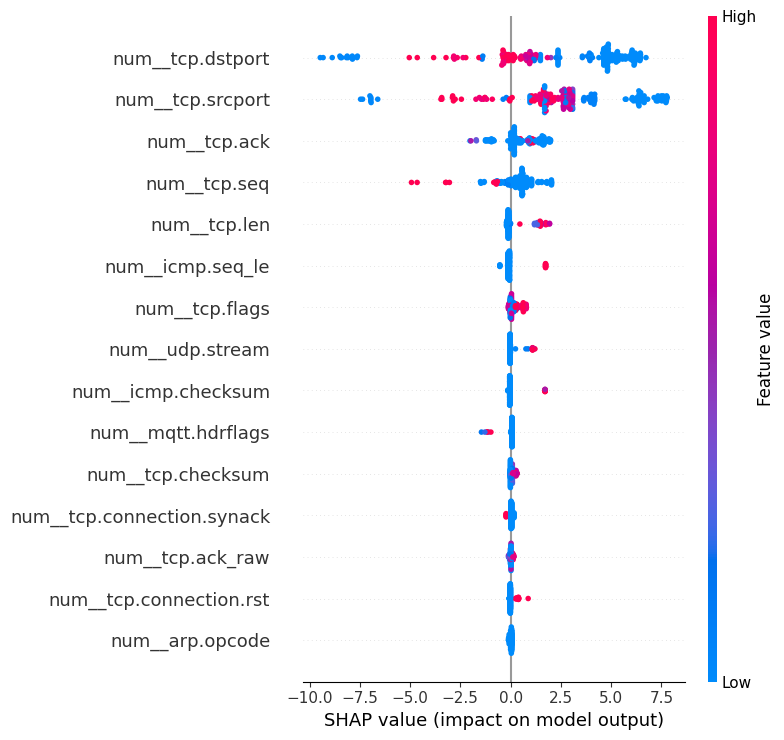

In [ ]:
# ============================================================
# 14. FAST SHAP
# ============================================================

SHAP_SAMPLES = min(200, len(X_test_scaled))

rng = np.random.default_rng(RANDOM_STATE)
shap_idx = rng.choice(
    len(X_test_scaled),
    size=SHAP_SAMPLES,
    replace=False
)

X_shap = X_test_scaled[shap_idx]

explainer = shap.TreeExplainer(tuned_xgb_model)

shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values

print("SHAP samples:", SHAP_SAMPLES)

# Feature names after preprocessing.
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = np.array(
        [f"feature_{i}" for i in range(X_train_scaled.shape[1])]
    )

shap.summary_plot(
    shap_values_plot,
    X_shap,
    feature_names=feature_names,
    max_display=15
)

## 15. Confusion Matrix — Tuned XGBoost

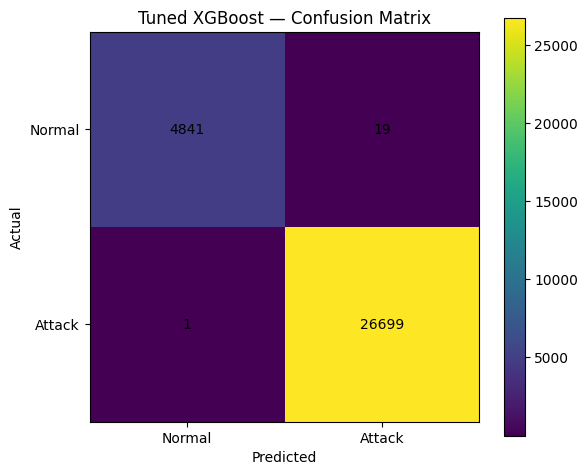

              precision    recall  f1-score   support

      Normal     0.9998    0.9961    0.9979      4860
      Attack     0.9993    1.0000    0.9996     26700

    accuracy                         0.9994     31560
   macro avg     0.9995    0.9980    0.9988     31560
weighted avg     0.9994    0.9994    0.9994     31560



In [ ]:
# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, tuned_xgb_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Tuned XGBoost — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["Normal", "Attack"])
plt.yticks([0, 1], ["Normal", "Attack"])
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    tuned_xgb_pred,
    target_names=["Normal", "Attack"],
    digits=4
))

## 16. ROC Curves

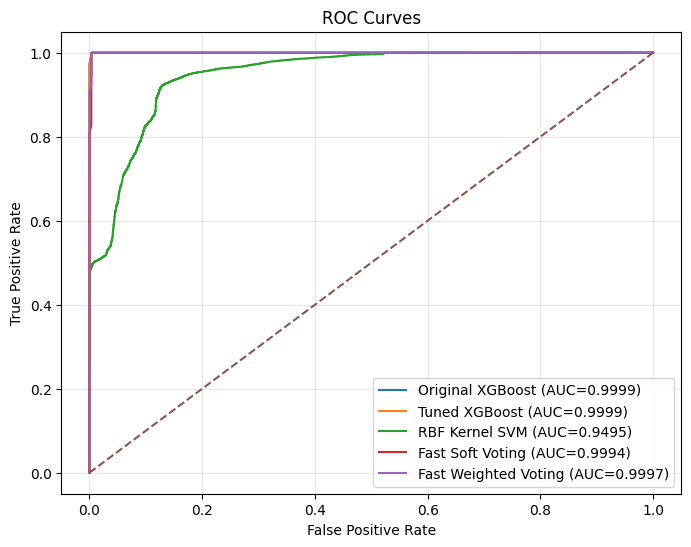

In [ ]:
# ============================================================
# 16. ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, prob in [
    ("Original XGBoost", original_xgb_proba),
    ("Tuned XGBoost", tuned_xgb_proba),
    ("RBF Kernel SVM", svm_proba),
    ("Fast Soft Voting", voting_prob),
    ("Fast Weighted Voting", weighted_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 17. Final Model Comparison

The test set is used for final evaluation. Compare the ensemble against the individual models, especially the tuned XGBoost baseline.

In [ ]:
# ============================================================
# 17. FINAL COMPARISON
# ============================================================

comparison = pd.DataFrame(results).set_index("Model")

comparison = comparison[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

print("========== FINAL COMPARISON TABLE ==========")
display(comparison.round(4))

print("\nTuned XGBoost baseline:")
print(f"Accuracy : {comparison.loc['Tuned XGBoost', 'Accuracy']:.4f}")
print(f"F1-Score : {comparison.loc['Tuned XGBoost', 'F1-Score']:.4f}")
print(f"Recall   : {comparison.loc['Tuned XGBoost', 'Recall']:.4f}")

print("\nFast ensemble results:")
display(
    comparison.loc[
        ["Fast Soft Voting", "Fast Weighted Voting"]
    ].round(4)
)

========== FINAL COMPARISON TABLE ==========


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.9994,0.9993,1.0000,0.9996,0.9999
Original XGBoost,0.9994,0.9993,1.0000,0.9996,0.9999
Tuned XGBoost,0.9994,0.9993,1.0000,0.9996,0.9999
RBF Kernel SVM,0.9284,0.9316,0.9879,0.9589,0.9495
Fast Soft Voting,0.9994,0.9993,1.0000,0.9996,0.9994
Fast Weighted Voting,0.9994,0.9993,1.0000,0.9996,0.9997



Tuned XGBoost baseline:
Accuracy : 0.9994
F1-Score : 0.9996
Recall   : 1.0000

Fast ensemble results:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Fast Soft Voting,0.9994,0.9993,1.0,0.9996,0.9994
Fast Weighted Voting,0.9994,0.9993,1.0,0.9996,0.9997


## 18. Optional Weka Integration

Weka is intentionally **disabled by default** because installing Java/Weka packages adds significant Colab startup time.

Set `RUN_WEKA = True` only if Weka results are required for your report.

In [ ]:
# ============================================================
# 18. OPTIONAL WEKA
# ============================================================

RUN_WEKA = False

if RUN_WEKA:
    print("Weka integration is optional and is disabled by default.")
    print("Enable RUN_WEKA=True and add the required Weka setup if needed.")
else:
    print("Weka skipped — fast Colab mode enabled.")

Weka skipped — fast Colab mode enabled.


## Notes for the research report

- `Attack_label` is the binary target.
- `Attack_type` is excluded from model features to prevent target leakage.
- High-cardinality raw packet/string fields are excluded to reduce overfitting and computational cost.
- The RBF SVM uses a bounded stratified training subset for runtime control.
- Soft Voting and Weighted Voting reuse existing model probabilities and therefore do not retrain the base models.
- SHAP uses a small reproducible sample for faster execution.
- The untouched test split is reserved for final model evaluation.